# 7 · Task-priority control

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Rudip1/learn-manipulator-control/blob/main/2_notebooks/exercises/07_task_priority.ipynb)

Theory: [`1_theory/07_task_priority.md`](../../1_theory/07_task_priority.md) · notation:
[`00_notation.md`](../../1_theory/00_notation.md)

In [1]:
# Install the module when it is not importable yet (Colab, fresh environment).
import importlib.util
if importlib.util.find_spec("manipulator_control") is None:
    %pip install -q git+https://github.com/Rudip1/learn-manipulator-control

In [2]:
import numpy as np
import matplotlib.pyplot as plt

import manipulator_control as mc
from manipulator_control import plotting

plt.rcParams.update({"figure.dpi": 80, "axes.grid": True})
np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(7)

## Recap

- Tasks $(\sigma_i, J_i)$ in priority order, each asking for $v_i = \dot\sigma_{d,i} + K_i\tilde\sigma_i$ (eqs. 7.1–7.2).
- Two tasks: $\dot q = J_1^\dagger v_1 + \bar J_2^\dagger(v_2 - J_2J_1^\dagger v_1)$ with the augmented Jacobian
  $\bar J_2 = J_2N_1$ (eqs. 7.3–7.4).
- $N$ tasks: $\dot q_i = \dot q_{i-1} + \bar J_i^{\#}(v_i - J_i\dot q_{i-1})$, $\bar J_i = J_iP_{i-1}$,
  $P_i = P_{i-1} - \bar J_i^\dagger\bar J_i$ (eqs. 7.5–7.6); $P_i$ projects onto the common null space (7.7).
- Compatible tasks are all met (= stacked pseudoinverse); conflicting ones are met in priority order.
- Algorithmic singularity: $\bar J_i$ loses rank while every $J_i$ is fine (7.8). DLS in (7.5) keeps it bounded;
  the singularity-robust form $\sum_i P_{i-1}J_i^{\#}v_i$ (7.10) avoids it at a loss of accuracy.

## Two tasks by hand

Equation (7.3) in NumPy, against the library's recursive solver. The two tasks conflict ($2 + 3 > 4$): task 1 is
met exactly, task 2 is not.

In [3]:
J1, J2 = rng.normal(size=(2, 4)), rng.normal(size=(3, 4))
v1, v2 = rng.normal(size=2), rng.normal(size=3)
J1p = np.linalg.pinv(J1)
N1 = np.eye(4) - J1p @ J1
qdot_hand = J1p @ v1 + np.linalg.pinv(J2 @ N1) @ (v2 - J2 @ J1p @ v1)
qdot_lib = mc.task_priority_velocity([mc.PriorityLevel(J1, v1), mc.PriorityLevel(J2, v2)], 4)
print("by hand:", qdot_hand, "\nlibrary:", qdot_lib)
print("task 1 residual:", np.linalg.norm(J1 @ qdot_lib - v1), "  task 2 residual:", np.linalg.norm(J2 @ qdot_lib - v2))

by hand: [-0.0887  8.4161 -4.3001  6.2146] 
library: [-0.0887  8.4161 -4.3001  6.2146]
task 1 residual: 9.283192408409472e-15   task 2 residual: 6.462013930185978


## The order decides who wins

The three-link arm with two position tasks — tip and the origin of joint 3 (DH frame 2) — is the example of
section 7.2. Each `FrameTask` recomputes its own Jacobian and error; the whole loop runs in C++.

tip > joint 3    final errors: {'tip': np.float64(0.0), 'joint 3': np.float64(0.0905)}
joint 3 > tip    final errors: {'joint 3': np.float64(0.0), 'tip': np.float64(0.0905)}


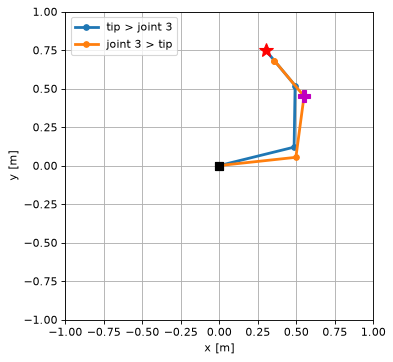

In [4]:
arm = mc.robots.planar([0.5, 0.4, 0.3])
model = mc.SerialArmModel(arm)
q0 = np.array([0.3, 0.7, 0.6])
T_tip, T_j3 = np.eye(4), np.eye(4)
T_tip[:2, 3] = [0.3, 0.75]
T_j3[:2, 3] = [0.55, 0.45]

def run_order(tip_first):
    tip = mc.FrameTask("tip", -1, [0, 1], T_tip)
    j3 = mc.FrameTask("joint 3", 2, [0, 1], T_j3)
    tip.set_gain(2.0); j3.set_gain(2.0)
    tasks = [tip, j3] if tip_first else [j3, tip]
    return tasks, mc.simulate_task_priority(model, q0, tasks, mc.PriorityConfig(), 0.01, 800)

fig, ax = plt.subplots(figsize=(5, 5))
for k, tip_first in enumerate([True, False]):
    tasks, r = run_order(tip_first)
    label = " > ".join(t.name for t in tasks)
    plotting.draw_planar_arm(ax, arm.frames(r.q[-1]), color=f"C{k}", label=label)
    print(f"{label:16s} final errors:", dict(zip([t.name for t in tasks], np.round(r.error_norm[-1], 4))))
ax.plot(*T_tip[:2, 3], "r*", markersize=13); ax.plot(*T_j3[:2, 3], "mP", markersize=11)
plotting.planar_axes(ax, limit=1.0); ax.legend(); plt.show()

## An algorithmic singularity

Task 1 holds the tip; task 2 drives joint 1. The norm of the augmented Jacobian $\bar J_2 = J_2N_1$ follows the
closed form (7.9) and vanishes at $q_3 = 0$, while $J_1$ stays far from singular.

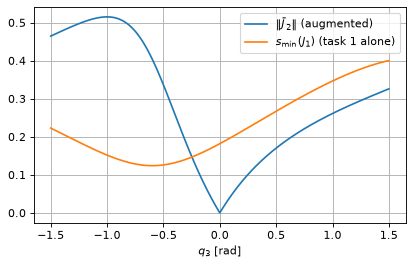

In [5]:
q3s = np.linspace(-1.5, 1.5, 301)
norm_bar, s_min = [], []
for q3 in q3s:
    J1 = mc.geometric_jacobian(arm, np.array([0.3, 0.7, q3]))[:2]
    norm_bar.append(np.linalg.norm(np.array([[1.0, 0, 0]]) @ mc.null_space_projector(J1)))
    s_min.append(mc.singular_values(J1)[-1])
plt.figure(figsize=(6, 3.5))
plt.plot(q3s, norm_bar, label=r"$\|\bar J_2\|$ (augmented)")
plt.plot(q3s, s_min, label=r"$s_{\min}(J_1)$ (task 1 alone)")
plt.xlabel("$q_3$ [rad]"); plt.legend(); plt.show()

Now ask for $q_1 = 1.7$ rad with the tip held. At most $1.479$ rad is reachable, at $q_3 = 0$, so the goal
drags the arm into the singularity.

pseudoinverse        peak |qdot|  680.17 rad/s   max tip error 1.4380 m   final q1 1.700
DLS λ=0.05           peak |qdot|   10.58 rad/s   max tip error 0.0062 m   final q1 1.478
singularity-robust   peak |qdot|    0.72 rad/s   max tip error 0.0003 m   final q1 1.451


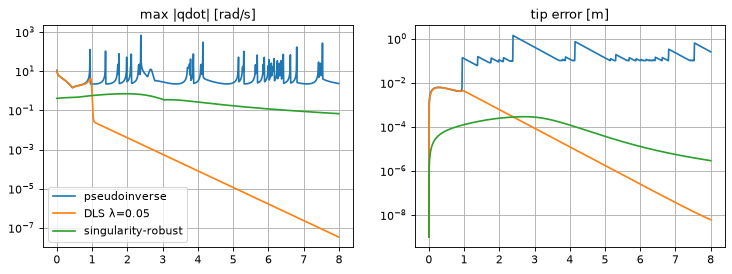

In [6]:
configs = {
    "pseudoinverse": mc.PriorityConfig(),
    "DLS λ=0.05": mc.PriorityConfig(inverse=mc.InverseMethod.DampedLeastSquares, damping=0.05),
    "singularity-robust": mc.PriorityConfig(method=mc.PriorityMethod.SingularityRobust),
}
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for k, (name, cfg) in enumerate(configs.items()):
    tip = mc.FrameTask("tip", -1, [0, 1], arm.end_effector(q0)); joint = mc.JointTask("q1", 0, 1.7)
    tip.set_gain(2.0); joint.set_gain(2.0)
    r = mc.simulate_task_priority(model, q0, [tip, joint], cfg, 0.01, 800)
    ax[0].semilogy(r.t[:-1], np.abs(r.u[:-1]).max(axis=1), label=name)
    ax[1].semilogy(r.t, r.error_norm[:, 0] + 1e-9, label=name)
    print(f"{name:20s} peak |qdot| {np.abs(r.u).max():7.2f} rad/s   max tip error {r.error_norm[:, 0].max():.4f} m   final q1 {r.q[-1, 0]:.3f}")
ax[0].set_title("max |qdot| [rad/s]"); ax[1].set_title("tip error [m]"); ax[0].legend(); plt.show()

## ✏️ Exercises

### ✏️ 1. The recursive solver

Implement eqs. (7.5)–(7.6) for a list of `(J, v)` pairs with the pseudoinverse. Use a tolerance,
`np.linalg.pinv(A, rcond=1e-10)`: once the tasks conflict, the projected Jacobians have singular values at
round-off level ($10^{-16}$) that must be treated as zero, not inverted.

In [7]:
def priority_recursive(levels, n):
    ### BEGIN SOLUTION
    qdot, P = np.zeros(n), np.eye(n)
    for J, v in levels:
        J_bar = J @ P
        J_bar_p = np.linalg.pinv(J_bar, rcond=1e-10)
        qdot = qdot + J_bar_p @ (v - J @ qdot)
        P = P - J_bar_p @ J_bar
    return qdot
    ### END SOLUTION

In [8]:
for _ in range(10):
    levels = [(rng.normal(size=(m, 6)), rng.normal(size=m)) for m in (2, 3, 2)]
    ref = mc.task_priority_velocity([mc.PriorityLevel(J, v) for J, v in levels], 6)
    assert np.allclose(priority_recursive(levels, 6), ref, atol=1e-9)
print("✓ priority_recursive")

✓ priority_recursive


### ✏️ 2. The singularity-robust solver

Implement eq. (7.10): $\dot q = \sum_i P_{i-1}J_i^\dagger v_i$ (projectors as in (7.6)).

In [9]:
def priority_sr(levels, n):
    ### BEGIN SOLUTION
    qdot, P = np.zeros(n), np.eye(n)
    for J, v in levels:
        qdot = qdot + P @ np.linalg.pinv(J, rcond=1e-10) @ v
        J_bar = J @ P
        P = P - np.linalg.pinv(J_bar, rcond=1e-10) @ J_bar
    return qdot
    ### END SOLUTION

In [10]:
sr = mc.PriorityConfig(method=mc.PriorityMethod.SingularityRobust)
for _ in range(10):
    levels = [(rng.normal(size=(m, 6)), rng.normal(size=m)) for m in (2, 2, 1)]
    ref = mc.task_priority_velocity([mc.PriorityLevel(J, v) for J, v in levels], 6, sr)
    assert np.allclose(priority_sr(levels, 6), ref, atol=1e-9)
print("✓ priority_sr")

✓ priority_sr


### ✏️ 3. Where is the algorithmic singularity?

For the tip-then-joint-1 hierarchy, write $\|\bar J_2\|$ in closed form (eq. 7.9) using the cross product of the
rows of $J_1$.

In [11]:
def norm_J2_bar(q, l2=0.4, l3=0.3):
    ### BEGIN SOLUTION
    J1 = mc.geometric_jacobian(arm, q)[:2]
    n = np.cross(J1[0], J1[1])
    return l2 * l3 * abs(np.sin(q[2])) / np.linalg.norm(n)
    ### END SOLUTION

In [12]:
for _ in range(20):
    q = rng.uniform(-np.pi, np.pi, 3)
    J1 = mc.geometric_jacobian(arm, q)[:2]
    if mc.singular_values(J1)[-1] < 1e-3:
        continue
    assert np.isclose(norm_J2_bar(q), np.linalg.norm(np.array([[1.0, 0, 0]]) @ mc.null_space_projector(J1)))
print("✓ norm_J2_bar")

✓ norm_J2_bar


### ✏️ 4. Compatible or not?

Two tasks are compatible at a configuration when the stacked Jacobian has rank $\operatorname{rank}J_1 +
\operatorname{rank}J_2$ (eq. 7.8). Write the test and use it on the tip/joint-1 hierarchy at $q_3 = 0.5$ and
$q_3 = 0$.

In [13]:
def compatible(J1, J2, tol=1e-9):
    ### BEGIN SOLUTION
    r = lambda A: np.linalg.matrix_rank(A, tol)
    return r(np.vstack([J1, J2])) == r(J1) + r(J2)
    ### END SOLUTION

In [14]:
J2 = np.array([[1.0, 0, 0]])
assert compatible(mc.geometric_jacobian(arm, np.array([0.3, 0.7, 0.5]))[:2], J2)
assert not compatible(mc.geometric_jacobian(arm, np.array([0.3, 0.7, 0.0]))[:2], J2)
print("✓ compatible")

✓ compatible


## 🔨 Break it

### 🔨 1. Forget the correction term

Drop $-J_i\dot q_{i-1}$ from (7.5) for three compatible tasks. The solver no longer meets the lower tasks — and it
is not even the singularity-robust method, because the inverse is still of the augmented Jacobian.

In [15]:
def priority_no_correction(levels, n):
    qdot, P = np.zeros(n), np.eye(n)
    for J, v in levels:
        J_bar = J @ P
        qdot = qdot + np.linalg.pinv(J_bar) @ v        # missing: - J @ qdot
        P = P - np.linalg.pinv(J_bar) @ J_bar
    return qdot

levels = [(rng.normal(size=(2, 7)), rng.normal(size=2)) for _ in range(3)]
for name, f in [("correct", priority_recursive), ("no correction", priority_no_correction)]:
    u = f(levels, 7)
    print(f"{name:14s} residuals:", [f"{np.linalg.norm(J @ u - v):.1e}" for J, v in levels])

correct        residuals: ['2.1e-15', '1.5e-15', '3.8e-15']
no correction  residuals: ['1.2e-15', '1.5e-01', '1.6e+00']


### 🔨 2. Project with the previous task only

Use $N_{i-1} = I - J_{i-1}^\dagger J_{i-1}$ instead of the accumulated $P_{i-1}$. Task 3 now moves freely in
directions that task 1 needs, and task 1 is disturbed.

In [16]:
def priority_local_projector(levels, n):
    qdot, P = np.zeros(n), np.eye(n)
    for J, v in levels:
        J_bar = J @ P
        qdot = qdot + np.linalg.pinv(J_bar) @ (v - J @ qdot)
        P = np.eye(n) - np.linalg.pinv(J) @ J            # wrong: forgets the tasks above
    return qdot

levels = [(rng.normal(size=(2, 5)), rng.normal(size=2)) for _ in range(3)]   # 6 > 5: they conflict
for name, f in [("accumulated P", priority_recursive), ("local N", priority_local_projector)]:
    u = f(levels, 5)
    print(f"{name:14s} task residuals:", [f"{np.linalg.norm(J @ u - v):.1e}" for J, v in levels])

accumulated P  task residuals: ['3.0e-14', '2.2e-14', '6.2e-01']
local N        task residuals: ['1.7e+00', '9.2e-16', '4.7e-16']


### 🔨 3. Safety last

Put the joint task *above* the tip task in the singularity scenario. Now joint 1 reaches 1.7 rad — and the tip,
which should have been held, wanders off.

In [17]:
tip = mc.FrameTask("tip", -1, [0, 1], arm.end_effector(q0)); joint = mc.JointTask("q1", 0, 1.7)
tip.set_gain(2.0); joint.set_gain(2.0)
r = mc.simulate_task_priority(model, q0, [joint, tip], mc.PriorityConfig(inverse=mc.InverseMethod.DampedLeastSquares), 0.01, 800)
print("final q1:", r.q[-1, 0], "  final tip error:", r.error_norm[-1, 1], "m")

final q1: 1.69999986046915   final tip error: 0.1030225814057847 m


## What to remember

- A hierarchy is a list of $(J_i, v_i)$; each level acts only in the null space left by all levels above it.
- Compatible tasks are all met; conflicting ones are met in priority order — the order is a design decision.
- The correction $-J_i\dot q_{i-1}$ and the *accumulated* projector $P_{i-1}$ are both essential.
- Algorithmic singularities come from the combination of tasks, not from the arm: damp the augmented inverse
  (or use the singularity-robust form and accept the lost accuracy).